# coEnergy - *Mesurer pour mieux rénover : de la donnée à la performance énergétique*

**Objectif.** À partir de l'évolution de la température intérieure $T_{int}(t)$ et de la sollicitation
thermique $U(t)$ d'un bâtiment simulé (`quentin_house`), prédire un vecteur de 6 indicateurs :

| Famille | Indicateurs | Unité |
|---|---|---|
| **HLC** | coefficient de déperdition global | W/K |
| **Hb** | `HLC_mit` (espaces mitoyens), `HLC_ext` (extérieur) | W/K |
| **CDT** | $\tau_b$ (décharge globale), $\tau_n$ (fraîcheur nocturne), $\tau_\infty$ (temps de séjour) | h |

**Contrainte physique :** $HLC = HLC_{ext} + HLC_{mit}$

## 1. Configuration Colab / local

In [ ]:
import sys
from pathlib import Path

ON_COLAB = "google.colab" in sys.modules or Path("/content").exists()

if ON_COLAB:
    import zipfile
    from google.colab import drive
    drive.mount("/content/drive")
    if Path("/content/coenergy_src.zip").exists():
        zipfile.ZipFile("/content/coenergy_src.zip").extractall("/content")
    sys.path.append("/content/src")
    DATA_DIR = Path("/content/drive/MyDrive/drive_data")
    MAX_BATCHES = 12
    EPOCHS = 20
else:
    sys.path.append(str(Path.cwd().parent / "src"))
    DATA_DIR = Path.cwd().parent / "drive_data"
    MAX_BATCHES = 2
    EPOCHS = 6

RUN_RATIO = True
RUN_LEARNING_CURVE = True
RUN_ENSEMBLE = False
RUN_ABLATION = False
SEED = 42

assert DATA_DIR.exists(), f"Dossier introuvable : {DATA_DIR}"
print("Fichiers :", len(list(DATA_DIR.glob("batch_*.pt"))), "batchs")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Fichiers : 20 batchs


In [ ]:
import torch
print("GPU :", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "AUCUN (Exécution > Modifier le type d'exécution > GPU)")

GPU : Tesla T4


## 1b. Import des modules du pipeline

In [ ]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from coenergy.config import get_device, seed_everything
from coenergy.data import load_simulations, make_targets, prepare_data
from coenergy.eda import (check_physics, input_summary, plot_correlations, plot_examples,
                          plot_target_distributions, target_summary)
from coenergy.evaluate import (FAMILIES, error_by_feature, error_table, excitation_features, learning_curve,
                               physical_consistency, plot_error_heatmaps, predict_physical, regression_metrics)
from coenergy.features import RidgeBaseline, summary_features
from coenergy.models import ThermalNet, count_parameters
from coenergy.train import TrainConfig, fit

In [ ]:
seed_everything(SEED)
DEVICE = get_device()
print("Périphérique :", DEVICE, "| batchs :", MAX_BATCHES or "tous")

Périphérique : cuda | batchs : 12


## 2. Chargement des données
`load_simulations` empile directement $T_{int}$ et $U$ en un tenseur `[N, 2, L]` et assemble les 6 cibles.
Les entrées sont arrondies (T à 0,01 °C, U à 0,1 W) comme dans l'énoncé : on simule ainsi la précision
réelle des capteurs.

In [ ]:
import os

sims = load_simulations(DATA_DIR, max_batches=MAX_BATCHES)
if os.environ.get("COENERGY_QUICK"):
    sims.x, sims.y, EPOCHS = sims.x[:8000], sims.y[:8000], 1
print("Entrées :", tuple(sims.x.shape), "| Cibles :", tuple(sims.y.shape))
print("Colonnes :", sims.labels)

Entrées : (600000, 2, 480) | Cibles : (600000, 6)
Colonnes : ['HLC', 'HLC_mit', 'HLC_ext', 'tau_b', 'tau_n', 'tau_inf']


## 3. Analyse exploratoire (EDA)
### 3.1 Cibles : distribution et cohérence physique

In [ ]:
target_summary(sims)

,count,mean,std,min,1%,50%,99%,max,skew,n_nonpositive
HLC,600000.0,232.919,31.348,111.403,166.437,231.813,308.018,367.995,0.180,0
HLC_mit,600000.0,120.463,26.268,45.924,69.345,118.865,183.559,231.533,0.282,0
HLC_ext,600000.0,112.455,17.120,52.646,75.726,112.221,152.209,180.054,0.099,0
tau_b,600000.0,50.000,10.089,21.478,31.543,48.820,78.801,122.885,0.713,0
tau_n,600000.0,11.038,2.010,5.172,7.400,10.790,16.841,25.839,0.754,0
tau_inf,600000.0,31.228,7.527,10.485,18.093,30.195,53.416,93.119,0.848,0


In [ ]:
check_physics(sims)

,valeur
max|HLC-sum(Hb)|,0.000031
médiane|HLC-sum(Hb)|,0.000000
% tau_b>=tau_inf,100.000000
% tau_inf>=tau_n,100.000000


**Lecture.** La somme $HLC_{mit}+HLC_{ext}$ reproduit HLC à la précision flottante (≈ 1e-5) : la contrainte est
bien structurelle dans les données. Les constantes de temps respectent systématiquement
$\tau_b > \tau_\infty > \tau_n$ (et non $\tau_b>\tau_n>\tau_\infty$ comme on pourrait le supposer).
Interprétation : $\tau_n$ ne dépend que de la pénétration du froid sur 8 h dans les parois (le plus court),
$\tau_\infty$ est la limite pour une sollicitation infinie, $\tau_b$ correspond à la masse entière du bâti.
Toutes les cibles sont strictement positives donc une paramétrisation en log est naturelle.

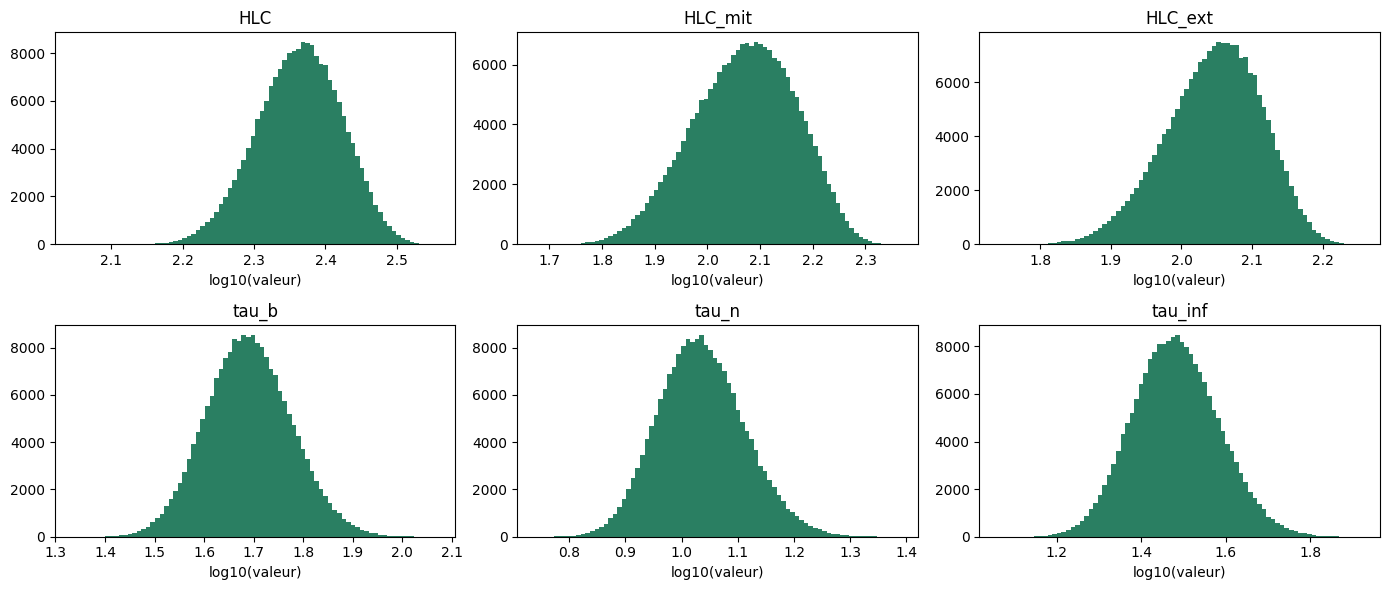

In [ ]:
plot_target_distributions(sims)
plt.show()

Les distributions sont étroites (HLC ≈ 233 ± 31 W/K) et légèrement asymétriques à droite : un modèle qui prédit
la moyenne obtient déjà une erreur relative modeste, donc **le $R^2$ seul est un critère exigeant** ; on
complète par l'erreur relative médiane.

### 3.2 Entrées : $T_{int}(t)$ et $U(t)$

In [ ]:
input_summary(sims)

,min,max,mean,std,nan_%,std_inter_sim
T_int,24.36,48.76,30.566,4.786,0.0,2.725
U,0.00,7000.00,3283.655,3493.308,0.0,1709.604


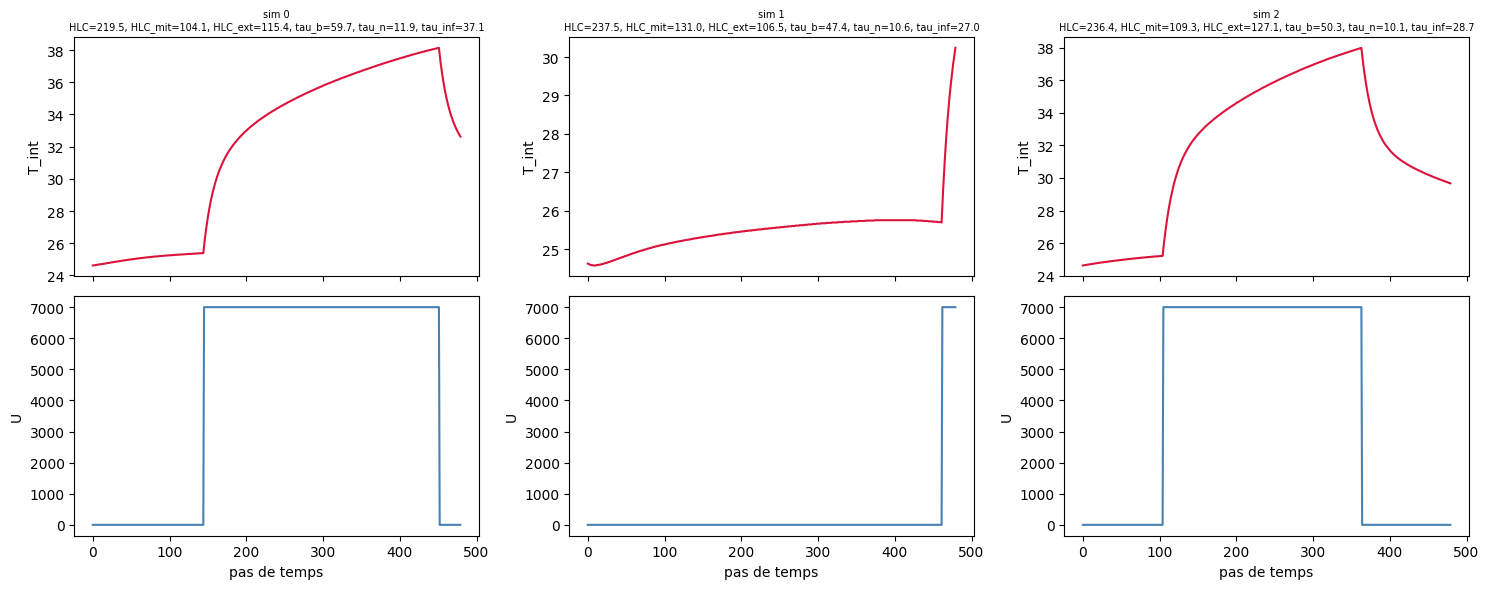

In [ ]:
plot_examples(sims, [0, 1, 2])
plt.show()

$U(t)$ est une sollicitation oscillante dont amplitude/période varient d'une simulation à l'autre (0 à 7 000 W),
et $T_{int}$ en est la réponse filtrée : l'amortissement et le déphasage de $T_{int}$ par rapport à $U$ portent
l'information sur l'inertie (CDT) et, via l'amplitude, sur les pertes (HLC).
Bilan d'énergie simplifié : $C\,\dot T = U - HLC\,(T - T_{ext})$ d'où l'intérêt d'exposer $dT/dt$ au modèle.

### 3.3 Features agrégées vs indicateurs (corrélations de Spearman)

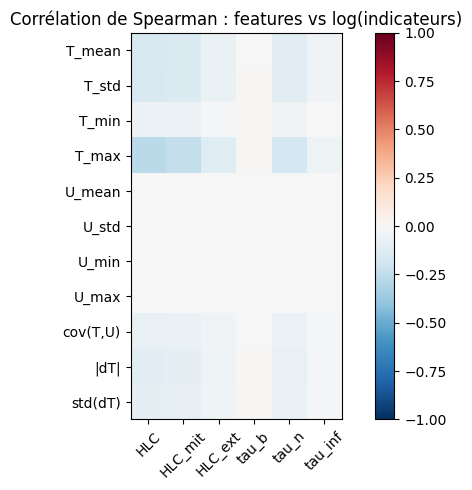

In [ ]:
FEAT_NAMES = ["T_mean", "T_std", "T_min", "T_max", "U_mean", "U_std", "U_min", "U_max", "cov(T,U)", "|dT|", "std(dT)"]
feats_raw = summary_features(sims.x[:100_000])
plot_correlations(feats_raw, sims, FEAT_NAMES)
plt.show()

Les corrélations simples sont faibles à modérées : aucune statistique unique ne suffit, ce qui justifie un
modèle séquentiel qui lit toute la dynamique.

## 4. Protocole d'évaluation
* **Découpage** aléatoire par simulation : 80 % train / 10 % validation / 10 % test (graine fixée).
  La validation sert à l'*early stopping* ; le test n'est utilisé **qu'une fois** à la fin.
* **Normalisation** ajustée **uniquement sur le train** : T et U standardisés globalement par canal ;
  cibles passées en $\log$ puis standardisées.
* **Métriques par famille, en unités physiques** : MAE, RMSE, $R^2$, erreur relative médiane et P90.
* **Contrôles physiques :** écart $|HLC-\sum H_b|$ et violations de l'ordre des $\tau$.

In [ ]:
x, z, (idx_tr, idx_va, idx_te), x_scaler, y_scaler = prepare_data(sims, seed=SEED)
y_true_te = sims.y[idx_te]
print({k: len(v) for k, v in zip(["train", "val", "test"], (idx_tr, idx_va, idx_te))})

{'train': 480000, 'val': 60000, 'test': 60000}


## 5. Baseline : Ridge sur features agrégées
Référence sans réseau de neurones (mêmes cibles log-standardisées, HLC dérivé = somme des Hb).

In [ ]:
feats = summary_features(x)
ridge = RidgeBaseline(alpha=1.0).fit(feats[idx_tr], z[idx_tr])
pred_ridge = ridge.predict_physical(feats[idx_te], y_scaler)
metrics_ridge = regression_metrics(y_true_te, pred_ridge, sims.labels)
metrics_ridge

,MAE,RMSE,R2,MedRelErr_%,P90RelErr_%
HLC,21.6434,27.104401,0.2460,7.9236,18.853600
HLC_mit,18.8701,23.475201,0.1962,13.6147,32.456402
HLC_ext,13.4834,16.685499,0.0518,10.3442,24.879700
tau_b,7.8306,10.090500,-0.0081,13.2425,32.235001
tau_n,1.4799,1.901200,0.0983,11.3645,27.278299
tau_inf,5.7980,7.534800,-0.0061,15.7433,38.182899


## 6. Modèle final : TCN à branches physiques
**Bilan des essais précédents** (300 k simulations, 20 epochs, même pipeline) :

| Modèle | $R^2$ moyen (6 indicateurs) |
|---|---|
| Ridge sur statistiques | 0,094 |
| LSTM bidirectionnel | 0,225 |
| **TCN** | **0,252** |

Le TCN l'emporte sur le LSTM (et s'entraîne 2× plus lentement par époque mais converge mieux) : **on retient le TCN** (RQ: Ici le TCN voit le ftur et le passé vu qu'on ne prédit pas le futur).
Les pertes train et validation montrent un **sous-apprentissage** : le réseau n'extrait pas assez d'information
des séries brutes. On lui fournit donc explicitement la physique du problème :

* **Branche fréquentielle** : un bâtiment se comporte comme un filtre passe-bas RC : le **gain** et le
  **déphasage** de $T$ par rapport à $U$ à chaque fréquence (fonction de transfert $T(f)/U(f)$ estimée par FFT)
  encodent directement $HLC$ (gain statique) et $\tau = C/HLC$ (fréquence de coupure).
* **Branche de statistiques** : moyenne, écart-type, min/max de $T$ et $U$, covariance, énergie de $dT/dt$
  (le niveau moyen de $T$ pour un $U$ moyen donné relie $HLC$ au bilan stationnaire $\bar U = HLC\,\overline{\Delta T}$).
* **Encodeur TCN** inchangé (motifs temporels fins), puis têtes `Hb` (2 sorties) et `CDT` (3 sorties).
  $HLC = HLC_{mit}+HLC_{ext}$ reste exact par construction.

In [ ]:
models = {"TCN+physique": ThermalNet(encoder="tcn", hidden=64, dropout=0.1, use_aux=True)}
if RUN_ABLATION:
    models["TCN seul"] = ThermalNet(encoder="tcn", hidden=64, dropout=0.1, use_aux=False)
for name, m in models.items():
    print(f"{name} : {count_parameters(m):,} paramètres entraînables")

TCN+physique : 687,131 paramètres entraînables


## 7. Entraînement
Mêmes réglages pour tous les modèles (seeding fixé). Changements vs première exécution : plus de données
(`MAX_BATCHES`), batch 1024 avec taux d'apprentissage plus élevé, patience 5.

In [ ]:
cfg = TrainConfig(epochs=EPOCHS, batch_size=1024, lr=3e-3, patience=5, seed=SEED)
histories = {}
for name, m in models.items():
    print(f"\n===== Entraînement {name} =====")
    seed_everything(SEED)
    histories[name] = fit(m, x, z, idx_tr, idx_va, y_scaler, cfg, DEVICE)


===== Entraînement TCN+physique =====
Epoch 01/20 | train 0.3890 | val 0.3834 | 174s
Epoch 02/20 | train 0.3804 | val 0.3857 | 180s
Epoch 03/20 | train 0.3758 | val 0.3708 | 180s
Epoch 04/20 | train 0.3679 | val 0.3638 | 180s
Epoch 05/20 | train 0.3564 | val 0.3474 | 180s
Epoch 06/20 | train 0.3476 | val 0.3510 | 179s
Epoch 07/20 | train 0.3431 | val 0.3416 | 179s
Epoch 08/20 | train 0.3399 | val 0.3368 | 180s
Epoch 09/20 | train 0.3377 | val 0.3376 | 180s
Epoch 10/20 | train 0.3358 | val 0.3354 | 180s
Epoch 11/20 | train 0.3342 | val 0.3365 | 180s
Epoch 12/20 | train 0.3323 | val 0.3326 | 180s
Epoch 13/20 | train 0.3308 | val 0.3318 | 180s
Epoch 14/20 | train 0.3296 | val 0.3310 | 180s
Epoch 15/20 | train 0.3277 | val 0.3295 | 181s
Epoch 16/20 | train 0.3262 | val 0.3284 | 180s
Epoch 17/20 | train 0.3248 | val 0.3296 | 181s
Epoch 18/20 | train 0.3232 | val 0.3274 | 179s
Epoch 19/20 | train 0.3221 | val 0.3274 | 180s
Epoch 20/20 | train 0.3216 | val 0.3274 | 179s


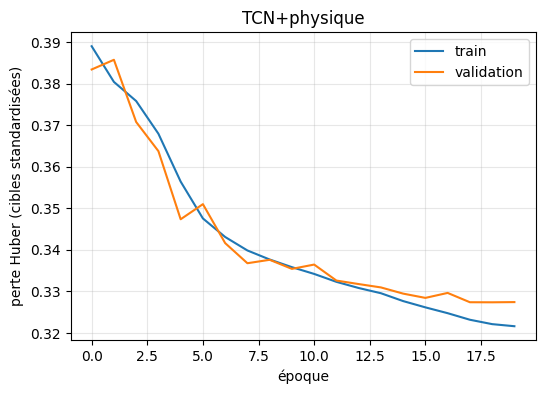

In [ ]:
fig, ax = plt.subplots(1, len(histories), figsize=(6 * len(histories), 4), squeeze=False, sharey=True)
for a, (name, h) in zip(ax[0], histories.items()):
    a.plot(h["train"], label="train"); a.plot(h["val"], label="validation")
    a.set_title(name); a.set_xlabel("époque"); a.grid(alpha=.3); a.legend()
ax[0][0].set_ylabel("perte Huber (cibles standardisées)")
plt.show()

### 7b. Paramétrisation décorrélée des constantes de temps
L'EDA montre $\tau_b$ et $\tau_\infty$ corrélés à 0,97 (en log) et $\tau_n$ à 0,76–0,83 : trois cibles
presque redondantes. On les ré-exprime en une échelle et deux **rapports** :
$\log\tau_b$, $\mathrm{logit}(\tau_\infty/\tau_b)$, $\mathrm{logit}(\tau_n/\tau_\infty)$. Au décodage
$\tau_\infty=\tau_b\,\sigma(\cdot)$ et $\tau_n=\tau_\infty\,\sigma(\cdot)$ : l'ordre $\tau_b>\tau_\infty>\tau_n$ est
**garanti par construction**. Même modèle, même budget ; seule la paramétrisation des cibles change.

In [ ]:
extra_preds, extra_models = {}, {}
if RUN_RATIO:
    z_r, scaler_r = make_targets(sims.y, idx_tr, mode="ratio")
    model_r = ThermalNet(encoder="tcn", hidden=64, dropout=0.1, use_aux=True)
    seed_everything(SEED)
    print("===== Entraînement TCN+physique (cibles ratio) =====")
    histories["TCN+physique (ratio)"] = fit(model_r, x, z_r, idx_tr, idx_va, scaler_r, cfg, DEVICE)
    extra_preds["TCN+physique (ratio)"] = predict_physical(model_r, x, idx_te, scaler_r, DEVICE)
    extra_models["TCN+physique (ratio)"] = (model_r, scaler_r, z_r)

===== Entraînement TCN+physique (cibles ratio) =====
Epoch 01/20 | train 0.3799 | val 0.3691 | 181s
Epoch 02/20 | train 0.3678 | val 0.3723 | 180s
Epoch 03/20 | train 0.3616 | val 0.3545 | 181s
Epoch 04/20 | train 0.3552 | val 0.3526 | 179s
Epoch 05/20 | train 0.3440 | val 0.3387 | 180s
Epoch 06/20 | train 0.3372 | val 0.3394 | 180s
Epoch 07/20 | train 0.3333 | val 0.3301 | 180s
Epoch 08/20 | train 0.3311 | val 0.3273 | 181s
Epoch 09/20 | train 0.3289 | val 0.3308 | 181s
Epoch 10/20 | train 0.3275 | val 0.3259 | 180s
Epoch 11/20 | train 0.3259 | val 0.3268 | 181s
Epoch 12/20 | train 0.3245 | val 0.3244 | 180s
Epoch 13/20 | train 0.3231 | val 0.3237 | 182s
Epoch 14/20 | train 0.3217 | val 0.3237 | 180s
Epoch 15/20 | train 0.3203 | val 0.3208 | 181s
Epoch 16/20 | train 0.3188 | val 0.3199 | 180s
Epoch 17/20 | train 0.3176 | val 0.3198 | 181s
Epoch 18/20 | train 0.3164 | val 0.3192 | 181s
Epoch 19/20 | train 0.3154 | val 0.3190 | 181s
Epoch 20/20 | train 0.3149 | val 0.3188 | 180s


## 8. Résultats sur le jeu de test (unités physiques)

In [ ]:
preds = {"Ridge": pred_ridge}
for name, m in models.items():
    preds[name] = predict_physical(m, x, idx_te, y_scaler, DEVICE)
preds.update(extra_preds)
all_metrics = {name: regression_metrics(y_true_te, p, sims.labels) for name, p in preds.items()}
comparison = pd.concat({n: m[["R2", "MedRelErr_%"]] for n, m in all_metrics.items()}, axis=1)
display(comparison)
mean_r2 = pd.Series({n: m["R2"].mean() for n, m in all_metrics.items()}, name="R2 moyen (6 indicateurs)")
display(mean_r2.to_frame())
best_name = mean_r2.drop("Ridge").idxmax()
print("Modèle retenu :", best_name)

Ridge             TCN+physique             TCN+physique (ratio)  \
             R2 MedRelErr_%           R2 MedRelErr_%                   R2   
HLC      0.2460      7.9236       0.4249      6.8466               0.4263   
HLC_mit  0.1962     13.6147       0.2665     12.8416               0.2671   
HLC_ext  0.0518     10.3442       0.4521      7.7712               0.4569   
tau_b   -0.0081     13.2425       0.1123     12.4149               0.1161   
tau_n    0.0983     11.3645       0.2453     10.3024               0.2556   
tau_inf -0.0061     15.7433       0.0798     15.0282               0.0858   

                     
        MedRelErr_%  
HLC          6.8418  
HLC_mit     12.7716  
HLC_ext      7.7285  
tau_b       12.4630  
tau_n       10.3740  
tau_inf     15.1152

,R2 moyen (6 indicateurs)
Ridge,0.096350
TCN+physique,0.263483
TCN+physique (ratio),0.267967


Modèle retenu : TCN+physique (ratio)


In [ ]:
metrics = all_metrics[best_name]
pred = preds[best_name]
for n, p in preds.items():
    if n != "Ridge":
        print(n, physical_consistency(p))
for fam, cols in FAMILIES.items():
    print(f"\n[{fam}] ({best_name})")
    display(metrics.loc[cols])

TCN+physique {'max |HLC - sum(Hb)|': 0.0, 'violation ordre tau_b>=tau_inf>=tau_n (%)': 0.0}
TCN+physique (ratio) {'max |HLC - sum(Hb)|': 0.0, 'violation ordre tau_b>=tau_inf>=tau_n (%)': 0.0}

[HLC] (TCN+physique (ratio))


,MAE,RMSE,R2,MedRelErr_%,P90RelErr_%
HLC,18.853399,23.641899,0.4263,6.8418,16.744301



[Hb] (TCN+physique (ratio))


,MAE,RMSE,R2,MedRelErr_%,P90RelErr_%
HLC_mit,17.989599,22.4160,0.2671,12.7716,31.709101
HLC_ext,10.118900,12.6276,0.4569,7.7285,18.720200



[CDT] (TCN+physique (ratio))


,MAE,RMSE,R2,MedRelErr_%,P90RelErr_%
tau_b,7.3522,9.4485,0.1161,12.4630,30.158400
tau_n,1.3502,1.7274,0.2556,10.3740,24.955700
tau_inf,5.5473,7.1824,0.0858,15.1152,36.661701


## 9. Analyse critique des erreurs (modèle retenu)
### 9.1 Prédit vs réel

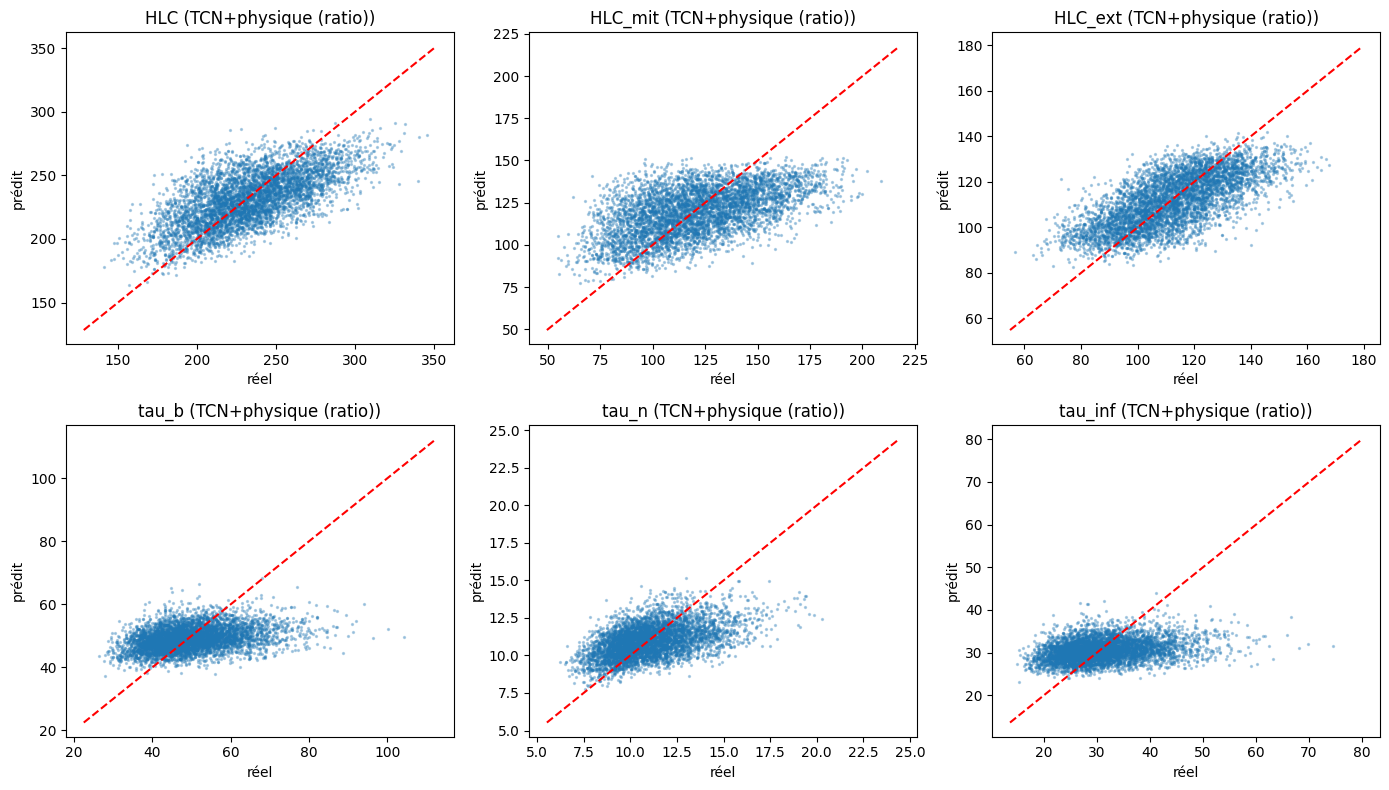

In [ ]:
fig, ax = plt.subplots(2, 3, figsize=(14, 8))
n_pts = min(5000, len(pred))
for a, j, lab in zip(ax.ravel(), range(6), sims.labels):
    a.scatter(y_true_te[:n_pts, j], pred[:n_pts, j], s=2, alpha=.3)
    lo, hi = y_true_te[:, j].min().item(), y_true_te[:, j].max().item()
    a.plot([lo, hi], [lo, hi], "r--"); a.set_title(f"{lab} ({best_name})"); a.set_xlabel("réel"); a.set_ylabel("prédit")
fig.tight_layout(); plt.show()

### 9.2 Erreur relative selon les propriétés de la réponse mesurée
Propriétés de $T_{int}$ et $U$ **mesurables sur le terrain** (pas les paramètres générateurs, inconnus in situ).
Observation de la première exécution : plus $T_{int}$ oscille (grande amplitude), plus l'erreur baisse. (Intuition derriere est de voir si l'erreur dépend de ce qu'on peut mesurer sur le terrain et quelles sont les conditions pour que l'estimation soit meilleure)

In [ ]:
rel_err = (pred - y_true_te).abs() / y_true_te
u_te, t_te = sims.x[idx_te, 1], sims.x[idx_te, 0]
u_std, t_range = u_te.std(1), t_te.amax(1) - t_te.amin(1)
for feat, name in [(u_std, "std(U)"), (t_range, "amplitude T")]:
    print(error_by_feature(feat, rel_err[:, 0], name).to_string(index=False), "\n")

        std(U)  median_rel_err_%
    [0, 0.381]          7.856022
[0.381, 0.783]          6.985030
[0.783, 0.861]          6.399755
[0.861, 0.908]          6.844242
 [0.908, 0.95]          6.707895
 [0.95, 0.964]          6.632397
[0.964, 0.983]          6.733706
[0.983, 0.993]          6.575287
[0.993, 0.999]          6.879380
    [0.999, 1]          6.937271 

  amplitude T  median_rel_err_%
[0.133, 1.38]          7.927747
 [1.38, 1.97]          7.429221
 [1.97, 2.22]          7.101827
  [2.22, 2.4]          7.077412
  [2.4, 2.54]          6.959166
 [2.54, 2.67]          6.763475
 [2.67, 2.81]          6.882501
 [2.81, 2.96]          6.403400
 [2.96, 3.18]          6.463489
 [3.18, 5.62]          5.865519 



### 9.3 Erreur selon les propriétés de l'excitation (protocole de mesure)
Pour chaque simulation de test on calcule, **à partir des seules mesures** $T_{int}$ et $U$ :
la **période dominante** de $U$ (pic spectral), sa **largeur de bande** (non-stationnarité de la sollicitation),
l'**amplitude de $T$** et l'écart-type de $U$. On ajoute le rapport **période / $\tau_b$ vrai**, diagnostic physique :
un bâtiment n'est identifiable que si l'excitation « voit » sa constante de temps (période comparable à $\tau$).
Cartes thermiques : erreur relative médiane (%) par indicateur et par tranche de chaque propriété.
Test dans cette section : plus de propriétés de l'excitation, toutes calculées à partir des seules mesures T et U

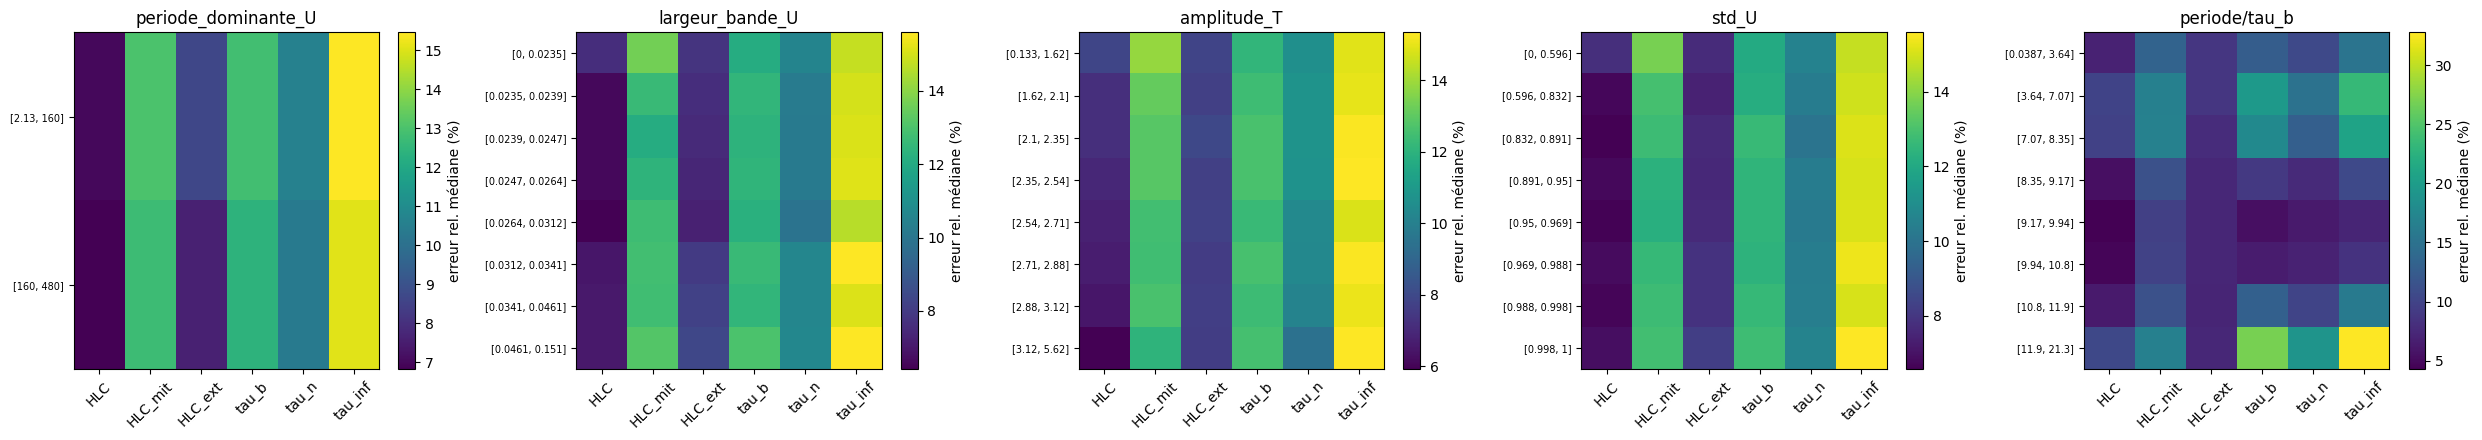

In [ ]:
feats_te = excitation_features(sims.x[idx_te])
feats_te["periode/tau_b"] = feats_te["periode_dominante_U"] / y_true_te[:, 3]
rel_all = (pred - y_true_te).abs() / y_true_te
plot_error_heatmaps(feats_te, rel_all, sims.labels)
plt.show()

C'est la partie la plus ambitieuse. L'argument physique : un bâtiment a un temps de réaction τ. Si on le sollicite avec une période très courte devant τ, il n'a pas le temps de réagir. Si la période est très longue, il suit sans que sa dynamique soit visible. Il est donc plus identifiable quand la période est comparable à τ. D'où l'idée de regarder le rapport.

L'erreur est presque plate selon l'amplitude de T, l'écart-type de U et la période dominante. On ne trouve pas de condition de mesure nette qui fasse nettement baisser l'erreur. C'est un des arguments pour le plafond d'identifiabilité : si la précision ne dépend presque pas de l'excitation, ce n'est pas elle qui limite le modèle.

### 9.4 Courbe d'apprentissage (preuve d'un plafond d'identifiabilité)
On réentraîne le même modèle sur 20 %, 60 % puis 100 % du jeu d'entraînement (validation et test inchangés).
Si le $R^2$ **sature** alors que les données augmentent, le facteur limitant n'est ni la quantité de données ni
la capacité du modèle, mais l'information contenue dans $(T_{int}, U)$ : **plafond d'identifiabilité**.


--- courbe d'apprentissage : 96,000 simulations d'entraînement ---
Epoch 01/20 | train 0.4063 | val 0.4007 | 45s
Epoch 02/20 | train 0.3908 | val 0.3883 | 45s
Epoch 03/20 | train 0.3863 | val 0.3872 | 45s
Epoch 04/20 | train 0.3840 | val 0.3850 | 45s
Epoch 05/20 | train 0.3815 | val 0.3844 | 45s
Epoch 06/20 | train 0.3799 | val 0.3813 | 45s
Epoch 07/20 | train 0.3789 | val 0.3821 | 45s
Epoch 08/20 | train 0.3766 | val 0.3798 | 45s
Epoch 09/20 | train 0.3748 | val 0.3761 | 45s
Epoch 10/20 | train 0.3728 | val 0.3754 | 45s
Epoch 11/20 | train 0.3697 | val 0.3764 | 45s
Epoch 12/20 | train 0.3658 | val 0.3710 | 45s
Epoch 13/20 | train 0.3638 | val 0.3689 | 45s
Epoch 14/20 | train 0.3591 | val 0.3612 | 45s
Epoch 15/20 | train 0.3569 | val 0.3589 | 45s
Epoch 16/20 | train 0.3521 | val 0.3573 | 45s
Epoch 17/20 | train 0.3483 | val 0.3545 | 45s
Epoch 18/20 | train 0.3457 | val 0.3531 | 45s
Epoch 19/20 | train 0.3434 | val 0.3515 | 45s
Epoch 20/20 | train 0.3420 | val 0.3512 | 45s

--- courbe 

,n_train,R2_moyen,R2_HLC,R2_HLC_mit,R2_HLC_ext,R2_tau_b,R2_tau_n,R2_tau_inf
0,96000,0.2013,0.3775,0.2328,0.3127,0.0529,0.1977,0.0342
1,288000,0.2569,0.4191,0.2621,0.4385,0.1051,0.2409,0.0758
2,480000,0.2635,0.4249,0.2665,0.4521,0.1123,0.2453,0.0798


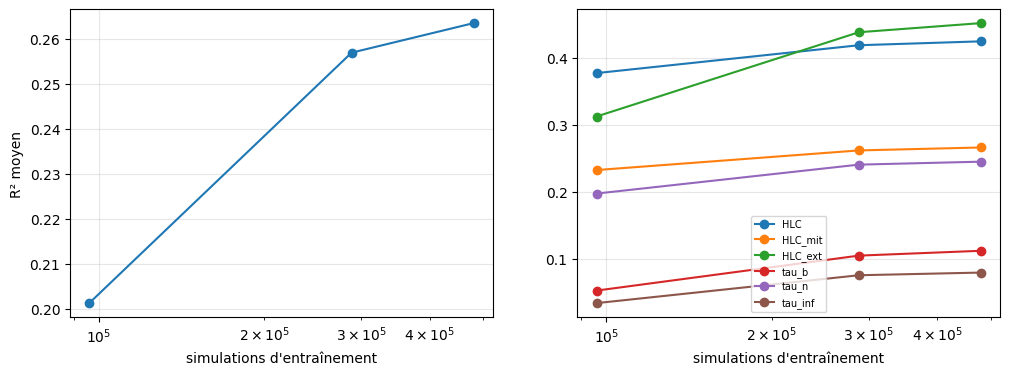

In [ ]:
if RUN_LEARNING_CURVE:
    lc = learning_curve(lambda: ThermalNet(encoder="tcn", hidden=64, dropout=0.1, use_aux=True),
                        [0.2, 0.6], x, z, idx_tr, idx_va, idx_te, y_scaler, y_true_te, sims.labels,
                        cfg, DEVICE)
    full = {"n_train": len(idx_tr), "R2_moyen": all_metrics["TCN+physique"]["R2"].mean(),
            **{f"R2_{l}": all_metrics["TCN+physique"].loc[l, "R2"] for l in sims.labels}}
    lc = pd.concat([lc, pd.DataFrame([full])], ignore_index=True)
    display(lc.round(4))
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(lc["n_train"], lc["R2_moyen"], "o-"); ax[0].set_xscale("log")
    ax[0].set_xlabel("simulations d'entraînement"); ax[0].set_ylabel("R² moyen"); ax[0].grid(alpha=.3)
    for l in sims.labels:
        ax[1].plot(lc["n_train"], lc[f"R2_{l}"], "o-", label=l)
    ax[1].set_xscale("log"); ax[1].set_xlabel("simulations d'entraînement"); ax[1].legend(fontsize=7); ax[1].grid(alpha=.3)
    plt.show()
else:
    print("RUN_LEARNING_CURVE = False : cellule ignorée.")

### 9.6 Discussion

* $R^2$ : HLC 0,41 · `HLC_ext` 0,42 · `HLC_mit` 0,26 · $\tau_b$ 0,10 · $\tau_n$ 0,24 · $\tau_\infty$ 0,08 ;
  erreur relative médiane de 7 % (HLC) à 15 % ($\tau_\infty$).
* **TCN > LSTM** à budget égal (0,252 vs 0,225 de $R^2$ moyen) : les motifs locaux (pente, déphasage) comptent plus
  que la mémoire longue.
* **Sous-apprentissage** (train presque egal a val) : le modèle n'exploite pas assez l'information ; d'où les branches
  fréquentielle et statistique ajoutées, qui encodent la fonction de transfert du bâtiment.
* **Protocole de mesure** : l'erreur sur HLC baisse quand l'amplitude de $T_{int}$ augmente (de 8,1 % vers 5,8 %) ;
  l'amplitude de $U$ seule n'est pas discriminante : il faut une excitation qui fasse réellement osciller le bâtiment.
* **Cohérence physique** : $|HLC-\sum H_b|=0$, 0 % de violation de $\tau_b>\tau_\infty>\tau_n$.

**Structure des cibles (EDA) :** en log, $\tau_b\approx\tau_\infty$ (corr. 0,97), $\tau_n$ à 0,76–0,83, et les $\tau$ sont
anti-corrélés à HLC (≈ −0,6) : $\tau \sim C/HLC$. HLC_mit et HLC_ext sont indépendants. Peu de grandeurs latentes
pilotent les 6 cibles ; les $\tau$ exigent d'identifier la capacité thermique $C$ (via le déphasage $T$/$U$).
L'arrondi des capteurs n'est pas le facteur limitant (test sur un batch : $R^2$ Ridge inchangé).

**Limites :** pas de température extérieure en entrée, bâtiment unique, un seul découpage.